Q1. Student Performance and Correlation Analysis
A college collects data on students' study hours, attendance, and examination marks.

(a) Create scatter plots for Study Hours vs Marks and Attendance vs Marks in separate subplots. Calculate Pearson's correlation coefficient for both pairs and determine which feature has the stronger linear association with marks. Support your conclusion with the correlation values.



Study Hours vs Marks: 0.9979
Attendance vs Marks: 0.9957


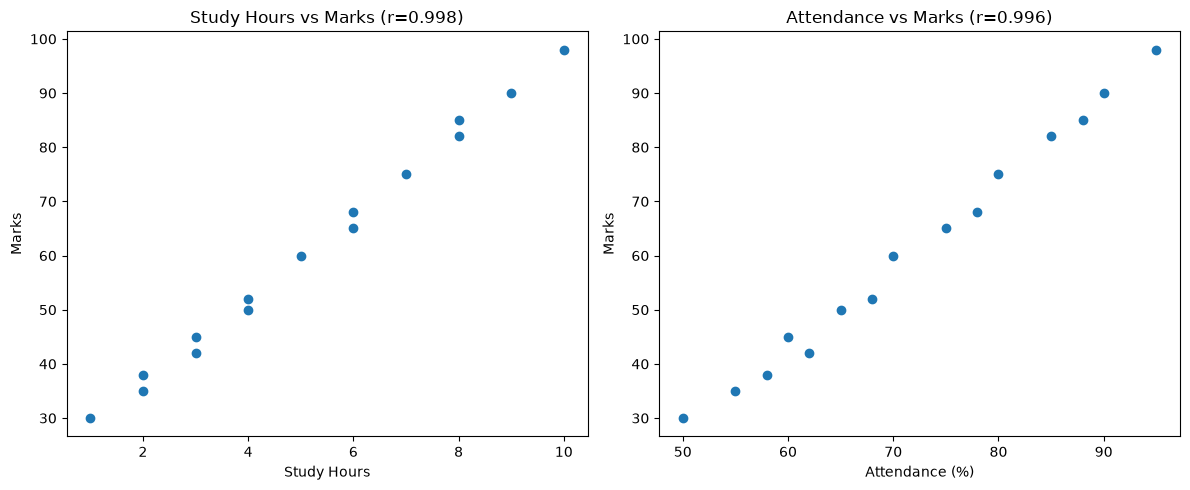

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 2, 4, 6, 8, 3],
    "Attendance": [50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 58, 68, 78, 88, 62],
    "Marks": [30, 35, 45, 50, 60, 65, 75, 82, 90, 98, 38, 52, 68, 85, 42]
})

r_study = np.corrcoef(df["Study_Hours"], df["Marks"])[0, 1]
r_attendance = np.corrcoef(df["Attendance"], df["Marks"])[0, 1]

print("Study Hours vs Marks:", round(r_study, 4))
print("Attendance vs Marks:", round(r_attendance, 4))

fig, a = plt.subplots(1, 2, figsize=(12, 5))

a[0].scatter(df["Study_Hours"], df["Marks"])
a[0].set_title(f"Study Hours vs Marks (r={r_study:.3f})")
a[0].set_xlabel("Study Hours")
a[0].set_ylabel("Marks")

a[1].scatter(df["Attendance"], df["Marks"])
a[1].set_title(f"Attendance vs Marks (r={r_attendance:.3f})")
a[1].set_xlabel("Attendance (%)")
a[1].set_ylabel("Marks")

plt.tight_layout()
plt.show()


(b) Add a hypothetical student with 1 study hour, 95% attendance, and 98 marks. Recalculate both correlations and visualize the updated data. Explain how this observation affects the correlation coefficients and why a single unusual observation can influence statistical conclusions.

Study Hours vs Marks: 0.7012
Attendance vs Marks: 0.9964


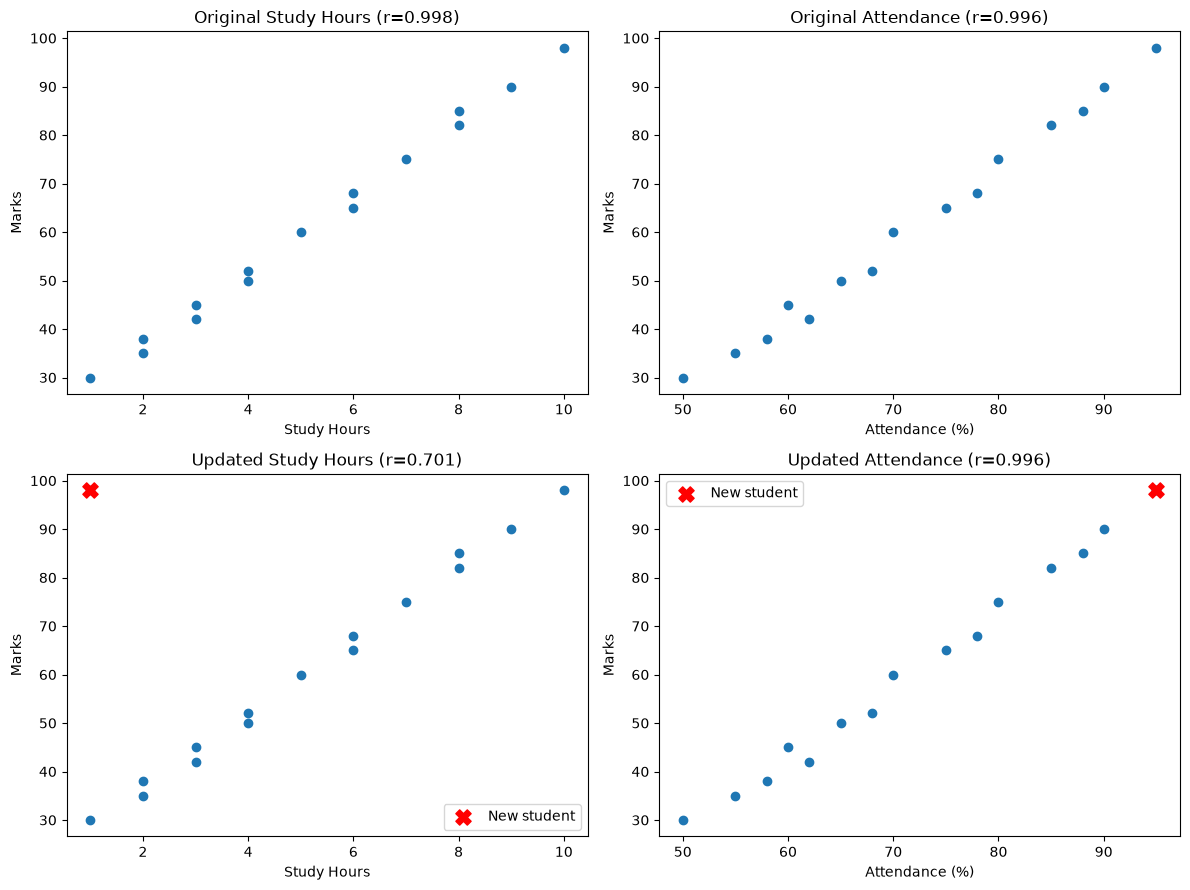

In [10]:
new_student = pd.DataFrame({
    "Study_Hours": [1],
    "Attendance": [95],
    "Marks": [98]
})

df_new = pd.concat([df, new_student], ignore_index=True)

new_r_study = np.corrcoef(df_new["Study_Hours"], df_new["Marks"])[0, 1]

new_r_attendance = np.corrcoef(df_new["Attendance"], df_new["Marks"])[0, 1]

print("Study Hours vs Marks:", round(new_r_study, 4))
print("Attendance vs Marks:", round(new_r_attendance, 4))

fig, b = plt.subplots(2, 2, figsize=(12, 9))

b[0, 0].scatter(df["Study_Hours"], df["Marks"])
b[0, 0].set_title(f"Original Study Hours (r={r_study:.3f})")
b[0, 0].set_xlabel("Study Hours")
b[0, 0].set_ylabel("Marks")

b[0, 1].scatter(df["Attendance"], df["Marks"])
b[0, 1].set_title(f"Original Attendance (r={r_attendance:.3f})")
b[0, 1].set_xlabel("Attendance (%)")
b[0, 1].set_ylabel("Marks")

b[1, 0].scatter(df_new["Study_Hours"], df_new["Marks"])
b[1, 0].scatter(1, 98, color="red", marker="X", s=120, label="New student")
b[1, 0].set_title(f"Updated Study Hours (r={new_r_study:.3f})")
b[1, 0].set_xlabel("Study Hours")
b[1, 0].set_ylabel("Marks")
b[1, 0].legend()

b[1, 1].scatter(df_new["Attendance"], df_new["Marks"])
b[1, 1].scatter(95, 98, color="red", marker="X", s=120, label="New student")
b[1, 1].set_title(f"Updated Attendance (r={new_r_attendance:.3f})")
b[1, 1].set_xlabel("Attendance (%)")
b[1, 1].set_ylabel("Marks")
b[1, 1].legend()


plt.tight_layout()
plt.show()

Q2. Product Sales: Bar Plot and Business Decisions
An electronics store records its sales and revenue across six products.

(a) Create a figure containing two bar plots comparing Units Sold and Revenue by product. Identify the highest and lowest products for each metric, calculate each product's percentage contribution to total revenue, and explain why the product with the highest unit sales may not generate the highest revenue.



Total Revenue: 5645000
Highest Units Sold: Mobile
Lowest Units Sold: Monitor
Highest Revenue: Laptop
Lowest Revenue: Keyboard

Revenue Contribution:
   Product  Revenue Revenue_Contribution_%
    Laptop  2250000                 39.86%
    Mobile  1800000                 31.89%
    Tablet   600000                 10.63%
Headphones   270000                  4.78%
   Monitor   525000                  9.30%
  Keyboard   200000                  3.54%


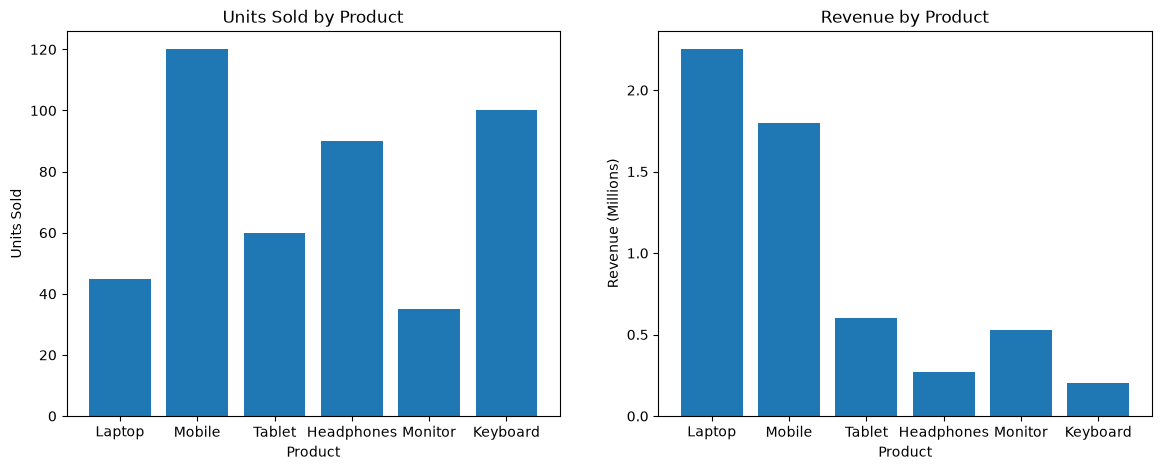

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Product": ["Laptop", "Mobile", "Tablet", "Headphones", "Monitor", "Keyboard"],
    "Units_Sold": [45, 120, 60, 90, 35, 100],
    "Revenue": [2250000, 1800000, 600000, 270000, 525000, 200000]
})

total_revenue = df["Revenue"].sum()
df["Revenue_Contribution_%"] = df["Revenue"] / total_revenue * 100

print("Total Revenue:", total_revenue)
print("Highest Units Sold:", df.loc[df["Units_Sold"].idxmax(), "Product"])
print("Lowest Units Sold:", df.loc[df["Units_Sold"].idxmin(), "Product"])
print("Highest Revenue:", df.loc[df["Revenue"].idxmax(), "Product"])
print("Lowest Revenue:", df.loc[df["Revenue"].idxmin(), "Product"])

print("\nRevenue Contribution:")
print(df[["Product", "Revenue", "Revenue_Contribution_%"]].to_string(
    index=False,
    formatters={"Revenue_Contribution_%": "{:.2f}%".format}
))

fig, c = plt.subplots(1, 2, figsize=(14, 5))

c[0].bar(df["Product"], df["Units_Sold"])
c[0].set_title("Units Sold by Product")
c[0].set_xlabel("Product")
c[0].set_ylabel("Units Sold")
c[0].tick_params(axis="x")

c[1].bar(df["Product"], df["Revenue"] / 1_000_000)
c[1].set_title("Revenue by Product")
c[1].set_xlabel("Product")
c[1].set_ylabel("Revenue (Millions)")
c[1].tick_params(axis="x")

(b) Calculate revenue per unit for every product and create a bar plot ranking products by this metric. Use Python to identify products with high unit sales but comparatively low revenue per unit, and recommend how the store should interpret these three metrics together.

Total Revenue: 5645000
Highest Units Sold: Mobile
Lowest Units Sold: Monitor
Highest Revenue: Laptop
Lowest Revenue: Keyboard

Revenue Contribution:
   Product  Revenue Revenue_Contribution_%
    Laptop  2250000                 39.86%
    Mobile  1800000                 31.89%
    Tablet   600000                 10.63%
Headphones   270000                  4.78%
   Monitor   525000                  9.30%
  Keyboard   200000                  3.54%


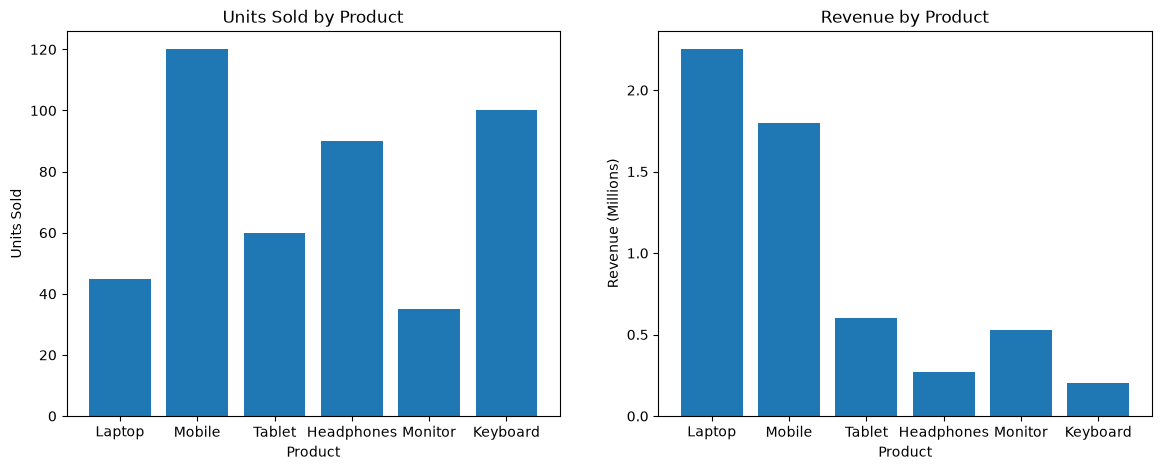

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Product": ["Laptop", "Mobile", "Tablet", "Headphones", "Monitor", "Keyboard"],
    "Units_Sold": [45, 120, 60, 90, 35, 100],
    "Revenue": [2250000, 1800000, 600000, 270000, 525000, 200000]
})

total_revenue = df["Revenue"].sum()
df["Revenue_Contribution_%"] = df["Revenue"] / total_revenue * 100

print("Total Revenue:", total_revenue)
print("Highest Units Sold:", df.loc[df["Units_Sold"].idxmax(), "Product"])
print("Lowest Units Sold:", df.loc[df["Units_Sold"].idxmin(), "Product"])
print("Highest Revenue:", df.loc[df["Revenue"].idxmax(), "Product"])
print("Lowest Revenue:", df.loc[df["Revenue"].idxmin(), "Product"])

print("\nRevenue Contribution:")
print(df[["Product", "Revenue", "Revenue_Contribution_%"]].to_string(
    index=False,
    formatters={"Revenue_Contribution_%": "{:.2f}%".format}
))

# Two bar plots in one figure
fig, d = plt.subplots(1, 2, figsize=(14, 5))

d[0].bar(df["Product"], df["Units_Sold"])
d[0].set_title("Units Sold by Product")
d[0].set_xlabel("Product")
d[0].set_ylabel("Units Sold")
d[0].tick_params(axis="x")

d[1].bar(df["Product"], df["Revenue"] / 1_000_000)
d[1].set_title("Revenue by Product")
d[1].set_xlabel("Product")
d[1].set_ylabel("Revenue (Millions)")
d[1].tick_params(axis="x")

Q3. Correlation Investigation Using the Tips Dataset
Use Seaborn's built-in tips dataset, which contains restaurant bills, tips, dining times, and party sizes.

(a) Create scatter plots for total_bill vs tip and size vs tip. Calculate the Pearson correlation coefficients for both relationships. Identify which pair has the stronger linear association and explain how the scatter plots support or challenge the numerical results.



Total Bill vs Tip: 0.6757
Party Size vs Tip: 0.4893


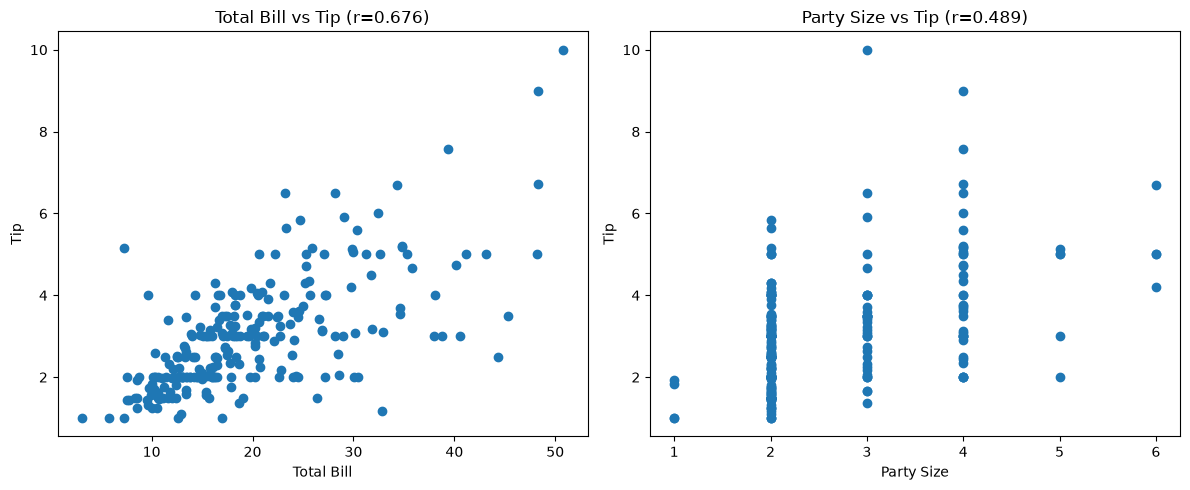

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("tips")

r_bill_tip = np.corrcoef(df["total_bill"], df["tip"])[0, 1]
r_size_tip = np.corrcoef(df["size"], df["tip"])[0, 1]

print("Total Bill vs Tip:", round(r_bill_tip, 4))
print("Party Size vs Tip:", round(r_size_tip, 4))

fig, e = plt.subplots(1, 2, figsize=(12, 5))

e[0].scatter(df["total_bill"], df["tip"])
e[0].set_title(f"Total Bill vs Tip (r={r_bill_tip:.3f})")
e[0].set_xlabel("Total Bill")
e[0].set_ylabel("Tip")

e[1].scatter(df["size"], df["tip"])
e[1].set_title(f"Party Size vs Tip (r={r_size_tip:.3f})")
e[1].set_xlabel("Party Size")
e[1].set_ylabel("Tip")

plt.tight_layout()
plt.show()

(b) Group the dataset by party size and calculate the average tip for each group. Create a bar plot of the average tip by party size, then compare the pattern in the grouped bar plot with the correlation between size and tip. Explain why grouped averages and individual-level correlation can tell different stories.

Average Tip by Party Size:
      mean  count
size             
1     1.44      4
2     2.58    156
3     3.39     38
4     4.14     37
5     4.03      5
6     5.22      4


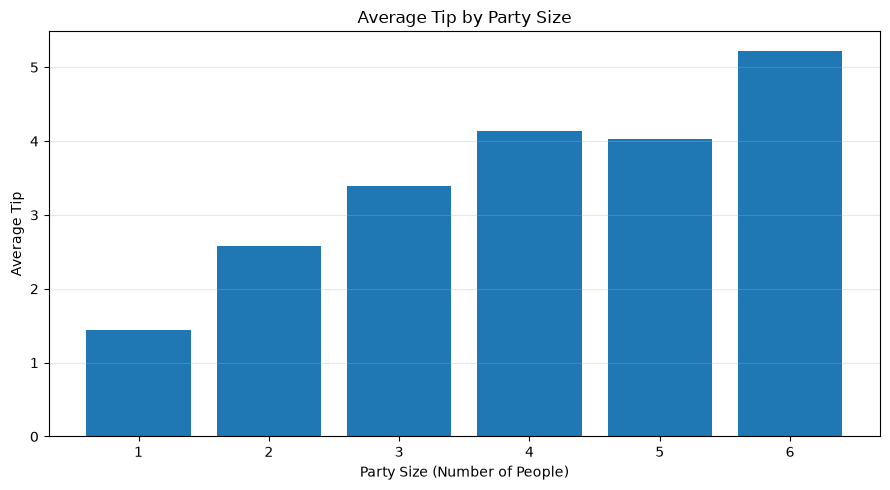

In [14]:
grouped = df.groupby("size")["tip"].agg(["mean", "count"])

print("Average Tip by Party Size:")
print(grouped.round(2))

plt.figure(figsize=(9, 5))
plt.bar(grouped.index, grouped["mean"])

plt.title("Average Tip by Party Size")
plt.xlabel("Party Size (Number of People)")
plt.ylabel("Average Tip")
plt.xticks(grouped.index)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Q4. Comparing Positive, Negative, and Weak Correlations
A marketing analyst investigates advertising expenditure and sales across different campaigns.

import pandas as pd
df = pd.DataFrame({"Campaign": [ "A", "B", "C", "D", "E", "F", "G", "H", "I", "J"    ],   
 "Advertising_Cost": [        10, 15, 20, 25, 30, 35, 40, 45, 50, 55    ],    
"Sales": [ 90, 80, 75, 70, 65, 60, 55, 50, 45, 40    ],    
"Customer_Satisfaction": [ 60, 75, 55, 85, 65, 70, 50, 80, 60, 75    ]})
(a) Create scatter plots for Advertising Cost vs Sales and Advertising Cost vs Customer Satisfaction. Calculate both Pearson correlation coefficients, classify each relationship as positive, negative, or weak, and justify your classifications using numerical evidence.



Advertising Cost vs Sales: -0.9965
Advertising Cost vs Customer Satisfaction: 0.0888


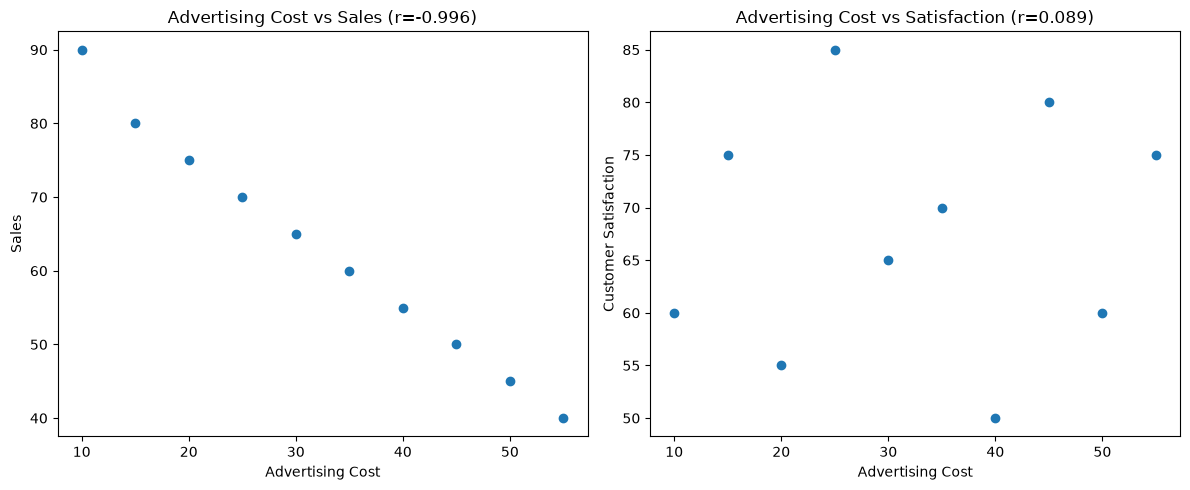

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Campaign": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"],
    "Advertising_Cost": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
    "Sales": [90, 80, 75, 70, 65, 60, 55, 50, 45, 40],
    "Customer_Satisfaction": [60, 75, 55, 85, 65, 70, 50, 80, 60, 75]
})

r_sales = np.corrcoef(
    df["Advertising_Cost"], df["Sales"]
)[0, 1]

r_satisfaction = np.corrcoef(
    df["Advertising_Cost"], df["Customer_Satisfaction"]
)[0, 1]

print("Advertising Cost vs Sales:", round(r_sales, 4))
print("Advertising Cost vs Customer Satisfaction:",
      round(r_satisfaction, 4))

fig, f = plt.subplots(1, 2, figsize=(12, 5))

f[0].scatter(df["Advertising_Cost"], df["Sales"])
f[0].set_title(f"Advertising Cost vs Sales (r={r_sales:.3f})")
f[0].set_xlabel("Advertising Cost")
f[0].set_ylabel("Sales")

f[1].scatter(
    df["Advertising_Cost"], df["Customer_Satisfaction"]
)
f[1].set_title(
    f"Advertising Cost vs Satisfaction (r={r_satisfaction:.3f})"
)
f[1].set_xlabel("Advertising Cost")
f[1].set_ylabel("Customer Satisfaction")

plt.tight_layout()
plt.show()


(b) Add a new campaign with an advertising cost of 100 and sales of 200. Recalculate the correlation between advertising cost and sales, plot the new point, and explain why correlation does not establish causation or guarantee that increased advertising will produce increased sales.

Original Correlation: -0.9965
Updated Correlation: 0.5684


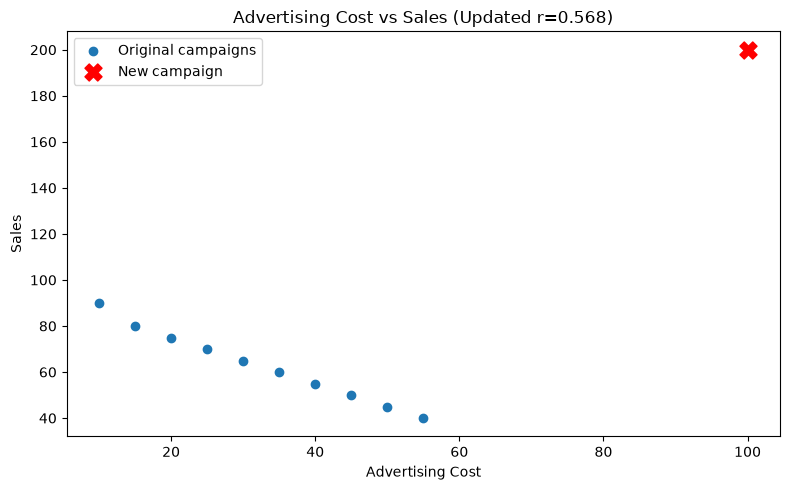

In [3]:
new_campaign = pd.DataFrame({
    "Advertising_Cost": [100],
    "Sales": [200]
})

sales_data = df[["Advertising_Cost", "Sales"]].copy()

updated_df = pd.concat(
    [sales_data, new_campaign],
    ignore_index=True
)

updated_r = np.corrcoef(
    updated_df["Advertising_Cost"],
    updated_df["Sales"]
)[0, 1]

print("Original Correlation:", round(r_sales, 4))
print("Updated Correlation:", round(updated_r, 4))

plt.figure(figsize=(8, 5))

plt.scatter(
    sales_data["Advertising_Cost"],
    sales_data["Sales"],
    label="Original campaigns"
)

plt.scatter(
    100, 200,
    color="red",
    marker="X",
    s=150,
    label="New campaign"
)

plt.title(f"Advertising Cost vs Sales (Updated r={updated_r:.3f})")
plt.xlabel("Advertising Cost")
plt.ylabel("Sales")
plt.legend()

plt.tight_layout()
plt.show()
